In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import urllib.request
urllib.request.urlretrieve(
    "https://ftp.ncbi.nlm.nih.gov/pub/clinvar/tab_delimited/variant_summary.txt.gz",
    "variant_summary.txt.gz"
)

('variant_summary.txt.gz', <http.client.HTTPMessage at 0x2021e2834d0>)

In [3]:
usecols = [
    "Type", "Name", "GeneSymbol", "ClinicalSignificance", "ClinSigSimple",
    "PhenotypeList", "Assembly", "Chromosome", "Start", "Stop",
    "ReferenceAllele", "AlternateAllele", "ReviewStatus", "NumberSubmitters"
]

In [4]:
df = pd.read_csv("variant_summary.txt.gz", sep="\t", usecols=usecols, low_memory=False)
df = df[df["Assembly"] == "GRCh38"]

In [5]:
df

,Type,Name,GeneSymbol,ClinicalSignificance,ClinSigSimple,PhenotypeList,Assembly,Chromosome,Start,Stop,ReferenceAllele,AlternateAllele,ReviewStatus,NumberSubmitters
1,Indel,NM_014855.3(AP5Z1):c.80_83delinsTGCTGTAAACTGTA...,AP5Z1,Pathogenic/Likely pathogenic,1,Hereditary spastic paraplegia 48|Macular dystr...,GRCh38,7,4781213,4781216,na,na,"criteria provided, multiple submitters, no con...",4
3,Deletion,NM_014855.3(AP5Z1):c.1413_1426del (p.Leu473fs),AP5Z1,Pathogenic,1,Hereditary spastic paraplegia 48,GRCh38,7,4787730,4787743,na,na,no assertion criteria provided,1
5,single nucleotide variant,NM_014630.3(ZNF592):c.3136G>A (p.Gly1046Arg),ZNF592,Uncertain significance,0,Galloway-Mowat syndrome 1,GRCh38,15,84799209,84799209,na,na,no assertion criteria provided,1
7,single nucleotide variant,NM_017547.4(FOXRED1):c.694C>T (p.Gln232Ter),FOXRED1,Pathogenic,1,"Mitochondrial complex I deficiency, nuclear ty...",GRCh38,11,126275389,126275389,na,na,"criteria provided, multiple submitters, no con...",6
9,single nucleotide variant,NM_017547.4(FOXRED1):c.1289A>G (p.Asn430Ser),FOXRED1,Likely pathogenic,1,"Mitochondrial complex I deficiency, nuclear ty...",GRCh38,11,126277517,126277517,na,na,"criteria provided, single submitter",2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9020425,single nucleotide variant,NM_004985.5(KRAS):c.454G>A (p.Val152Ile),KRAS,Likely pathogenic,1,Noonan syndrome 3,GRCh38,12,25209908,25209908,na,na,"criteria provided, single submitter",1
9020427,single nucleotide variant,NM_003611.3(OFD1):c.243C>A (p.His81Gln),OFD1,Likely pathogenic,1,Orofaciodigital syndrome I,GRCh38,X,13736609,13736609,na,na,"criteria provided, single submitter",1
9020429,single nucleotide variant,NM_003070.5(SMARCA2):c.4466A>G (p.Tyr1489Cys),SMARCA2,Likely pathogenic,1,Blepharophimosis-impaired intellectual develop...,GRCh38,9,2186100,2186100,na,na,"criteria provided, single submitter",1
9020431,single nucleotide variant,NM_001081550.2(THOC2):c.2696A>G (p.Tyr899Cys),THOC2,Likely pathogenic,1,X-linked intellectual disability-short stature...,GRCh38,X,123627754,123627754,na,na,"criteria provided, single submitter",1


In [6]:
df["ReviewStatus"].value_counts()

ReviewStatus
criteria provided, single submitter                     3253423
criteria provided, multiple submitters, no conflicts     666539
-                                                        245084
criteria provided, conflicting classifications           164827
no assertion criteria provided                           116475
reviewed by expert panel                                  22041
no classification provided                                 7186
no classification for the single variant                    683
no classifications from unflagged records                   146
practice guideline                                           54
Name: count, dtype: int64

In [7]:
good_review = [
    "criteria provided, multiple submitters, no conflicts",
    "reviewed by expert panel",
    "practice guideline"
]
df = df[df["ReviewStatus"].isin(good_review)]

In [8]:
df

,Type,Name,GeneSymbol,ClinicalSignificance,ClinSigSimple,PhenotypeList,Assembly,Chromosome,Start,Stop,ReferenceAllele,AlternateAllele,ReviewStatus,NumberSubmitters
1,Indel,NM_014855.3(AP5Z1):c.80_83delinsTGCTGTAAACTGTA...,AP5Z1,Pathogenic/Likely pathogenic,1,Hereditary spastic paraplegia 48|Macular dystr...,GRCh38,7,4781213,4781216,na,na,"criteria provided, multiple submitters, no con...",4
7,single nucleotide variant,NM_017547.4(FOXRED1):c.694C>T (p.Gln232Ter),FOXRED1,Pathogenic,1,"Mitochondrial complex I deficiency, nuclear ty...",GRCh38,11,126275389,126275389,na,na,"criteria provided, multiple submitters, no con...",6
13,single nucleotide variant,NM_000410.4(HFE):c.845G>A (p.Cys282Tyr),HFE,"Pathogenic/Pathogenic, low penetrance; risk fa...",1,Hemochromatosis type 1|not provided|Hereditary...,GRCh38,6,26092913,26092913,na,na,"criteria provided, multiple submitters, no con...",58
25,single nucleotide variant,NM_000410.4(HFE):c.157G>A (p.Val53Met),HFE,Uncertain significance,0,HFE POLYMORPHISM|Hemochromatosis type 1|not pr...,GRCh38,6,26090921,26090921,na,na,"criteria provided, multiple submitters, no con...",3
27,single nucleotide variant,NM_000410.4(HFE):c.175G>A (p.Val59Met),HFE,Uncertain significance,0,HFE POLYMORPHISM|Hemochromatosis type 1|not sp...,GRCh38,6,26090939,26090939,na,na,"criteria provided, multiple submitters, no con...",3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8992020,Deletion,NM_000419.5(ITGA2B):c.963del (p.His322fs),ITGA2B,Pathogenic,1,Glanzmann thrombasthenia,GRCh38,17,44383929,44383929,na,na,reviewed by expert panel,1
8992022,single nucleotide variant,NM_000419.5(ITGA2B):c.2841+1G>T,ITGA2B,Likely pathogenic,1,Glanzmann thrombasthenia,GRCh38,17,44374997,44374997,na,na,reviewed by expert panel,1
8992557,single nucleotide variant,NM_181523.3(PIK3R1):c.1300-3T>C,PIK3R1,Likely benign,0,PIK3R1-related immunodeficiency and SHORT synd...,GRCh38,5,68293706,68293706,na,na,reviewed by expert panel,1
8992559,Deletion,NM_181523.3(PIK3R1):c.1644_1648del (p.Asp548fs),PIK3R1,Pathogenic,1,PIK3R1-related immunodeficiency and SHORT synd...,GRCh38,5,68295221,68295225,na,na,reviewed by expert panel,1


In [9]:
print("Filtrelenmiş ham veri:", df.shape)

Filtrelenmiş ham veri: (688634, 14)


In [10]:
def map_label(cs):
    cs = str(cs)
    if "Conflicting" in cs:
        return None
    if "Pathogenic" in cs:
        return 1
    if "Benign" in cs:
        return 0
    return None

In [11]:
df["label"] = df["ClinicalSignificance"].apply(map_label)
train_df = df.dropna(subset=["label"]).copy()
vus_df = df[df["ClinicalSignificance"] == "Uncertain significance"].copy()

print("Train (Benign/Pathogenic):", train_df.shape)
print("VUS:", vus_df.shape)
print(train_df["label"].value_counts())

C:\Users\ahmet\AppData\Local\Temp\ipykernel_10536\2165575553.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["label"] = df["ClinicalSignificance"].apply(map_label)


Train (Benign/Pathogenic): (239734, 15)
VUS: (301751, 15)
label
0.0    157528
1.0     82206
Name: count, dtype: int64


In [14]:
train_df[train_df["ClinicalSignificance"].str.contains("Pathogenic") & train_df["ClinicalSignificance"].str.contains("Benign")]

,Type,Name,GeneSymbol,ClinicalSignificance,ClinSigSimple,PhenotypeList,Assembly,Chromosome,Start,Stop,ReferenceAllele,AlternateAllele,ReviewStatus,NumberSubmitters,label


In [16]:
train_df

,Type,Name,GeneSymbol,ClinicalSignificance,ClinSigSimple,PhenotypeList,Assembly,Chromosome,Start,Stop,ReferenceAllele,AlternateAllele,ReviewStatus,NumberSubmitters,label
1,Indel,NM_014855.3(AP5Z1):c.80_83delinsTGCTGTAAACTGTA...,AP5Z1,Pathogenic/Likely pathogenic,1,Hereditary spastic paraplegia 48|Macular dystr...,GRCh38,7,4781213,4781216,na,na,"criteria provided, multiple submitters, no con...",4,1.0
7,single nucleotide variant,NM_017547.4(FOXRED1):c.694C>T (p.Gln232Ter),FOXRED1,Pathogenic,1,"Mitochondrial complex I deficiency, nuclear ty...",GRCh38,11,126275389,126275389,na,na,"criteria provided, multiple submitters, no con...",6,1.0
13,single nucleotide variant,NM_000410.4(HFE):c.845G>A (p.Cys282Tyr),HFE,"Pathogenic/Pathogenic, low penetrance; risk fa...",1,Hemochromatosis type 1|not provided|Hereditary...,GRCh38,6,26092913,26092913,na,na,"criteria provided, multiple submitters, no con...",58,1.0
33,single nucleotide variant,NM_000410.4(HFE):c.848A>C (p.Gln283Pro),HFE,Pathogenic/Likely pathogenic,1,Hemochromatosis type 1|Hereditary hemochromato...,GRCh38,6,26092916,26092916,na,na,"criteria provided, multiple submitters, no con...",5,1.0
49,single nucleotide variant,NM_001042472.3(ABHD12):c.1054C>T (p.Arg352Ter),ABHD12,Pathogenic,1,PHARC syndrome|not provided,GRCh38,20,25302322,25302322,na,na,"criteria provided, multiple submitters, no con...",5,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8988011,single nucleotide variant,NM_001429.4(EP300):c.3729-2A>G,EP300,Pathogenic/Likely pathogenic,1,Menke-Hennekam syndrome 2|Rubinstein-Taybi syn...,GRCh38,22,41164051,41164051,na,na,"criteria provided, multiple submitters, no con...",2,1.0
8991073,Deletion,NM_024675.4(PALB2):c.221del (p.Asn74fs),PALB2,Pathogenic,1,Familial cancer of breast|Hereditary cancer-pr...,GRCh38,16,23636325,23636325,na,na,"criteria provided, multiple submitters, no con...",2,1.0
8992018,Deletion,NM_000212.3(ITGB3):c.1788del (p.Ser596fs),ITGB3,Pathogenic,1,Glanzmann thrombasthenia,GRCh38,17,47299405,47299405,na,na,reviewed by expert panel,1,1.0
8992020,Deletion,NM_000419.5(ITGA2B):c.963del (p.His322fs),ITGA2B,Pathogenic,1,Glanzmann thrombasthenia,GRCh38,17,44383929,44383929,na,na,reviewed by expert panel,1,1.0


In [17]:
df

,Type,Name,GeneSymbol,ClinicalSignificance,ClinSigSimple,PhenotypeList,Assembly,Chromosome,Start,Stop,ReferenceAllele,AlternateAllele,ReviewStatus,NumberSubmitters,label
1,Indel,NM_014855.3(AP5Z1):c.80_83delinsTGCTGTAAACTGTA...,AP5Z1,Pathogenic/Likely pathogenic,1,Hereditary spastic paraplegia 48|Macular dystr...,GRCh38,7,4781213,4781216,na,na,"criteria provided, multiple submitters, no con...",4,1.0
7,single nucleotide variant,NM_017547.4(FOXRED1):c.694C>T (p.Gln232Ter),FOXRED1,Pathogenic,1,"Mitochondrial complex I deficiency, nuclear ty...",GRCh38,11,126275389,126275389,na,na,"criteria provided, multiple submitters, no con...",6,1.0
13,single nucleotide variant,NM_000410.4(HFE):c.845G>A (p.Cys282Tyr),HFE,"Pathogenic/Pathogenic, low penetrance; risk fa...",1,Hemochromatosis type 1|not provided|Hereditary...,GRCh38,6,26092913,26092913,na,na,"criteria provided, multiple submitters, no con...",58,1.0
25,single nucleotide variant,NM_000410.4(HFE):c.157G>A (p.Val53Met),HFE,Uncertain significance,0,HFE POLYMORPHISM|Hemochromatosis type 1|not pr...,GRCh38,6,26090921,26090921,na,na,"criteria provided, multiple submitters, no con...",3,NaN
27,single nucleotide variant,NM_000410.4(HFE):c.175G>A (p.Val59Met),HFE,Uncertain significance,0,HFE POLYMORPHISM|Hemochromatosis type 1|not sp...,GRCh38,6,26090939,26090939,na,na,"criteria provided, multiple submitters, no con...",3,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8992020,Deletion,NM_000419.5(ITGA2B):c.963del (p.His322fs),ITGA2B,Pathogenic,1,Glanzmann thrombasthenia,GRCh38,17,44383929,44383929,na,na,reviewed by expert panel,1,1.0
8992022,single nucleotide variant,NM_000419.5(ITGA2B):c.2841+1G>T,ITGA2B,Likely pathogenic,1,Glanzmann thrombasthenia,GRCh38,17,44374997,44374997,na,na,reviewed by expert panel,1,NaN
8992557,single nucleotide variant,NM_181523.3(PIK3R1):c.1300-3T>C,PIK3R1,Likely benign,0,PIK3R1-related immunodeficiency and SHORT synd...,GRCh38,5,68293706,68293706,na,na,reviewed by expert panel,1,NaN
8992559,Deletion,NM_181523.3(PIK3R1):c.1644_1648del (p.Asp548fs),PIK3R1,Pathogenic,1,PIK3R1-related immunodeficiency and SHORT synd...,GRCh38,5,68295221,68295225,na,na,reviewed by expert panel,1,1.0


In [18]:
extra_cols = pd.read_csv(
    "variant_summary.txt.gz", sep="\t",
    usecols=["PositionVCF", "ReferenceAlleleVCF", "AlternateAlleleVCF"],
    low_memory=False
)

In [19]:
train_df = train_df.join(extra_cols)
train_df = train_df[
    (train_df["ReferenceAlleleVCF"] != "na") &
    (train_df["AlternateAlleleVCF"] != "na")
].copy()

In [20]:
snv_df = train_df[train_df["Type"] == "single nucleotide variant"].copy()
snv_df["hgvs_id"] = (
    "chr" + snv_df["Chromosome"].astype(str) + ":g." +
    snv_df["PositionVCF"].astype(int).astype(str) +
    snv_df["ReferenceAlleleVCF"] + ">" + snv_df["AlternateAlleleVCF"]
)

In [21]:
print("SNV sayısı:", snv_df.shape)


SNV sayısı: (202286, 19)


In [22]:
url = "https://myvariant.info/v1/variant"
fields = "dbnsfp.cadd.phred,gnomad_genome.af.af,dbnsfp.phylop.100way_vertebrate"

In [23]:
def flatten_result(r):
    dbnsfp = r.get("dbnsfp", {})
    phylop = dbnsfp.get("phylop", {}).get("100way_vertebrate", {})
    return {
        "hgvs_id": r.get("query"),
        "cadd_phred": dbnsfp.get("cadd", {}).get("phred"),
        "gnomad_af": r.get("gnomad_genome", {}).get("af", {}).get("af"),
        "phylop_100way": phylop.get("score") if isinstance(phylop, dict) else None,
        "notfound": r.get("notfound", False)
    }

In [24]:
all_ids = snv_df["hgvs_id"].tolist()
batch_size = 1000
results = []

In [26]:
import requests
import time

In [27]:
for i in range(0, len(all_ids), batch_size):
    batch = all_ids[i:i+batch_size]
    r = requests.post(url, data={"ids": ",".join(batch), "fields": fields, "assembly": "hg38"})
    r.raise_for_status()
    results.extend([flatten_result(x) for x in r.json()])
    print(f"{i+len(batch)}/{len(all_ids)} tamamlandı")
    time.sleep(0.2)

annot_df = pd.DataFrame(results)

# KAYDET — kernel düşerse tekrar API'ye gitmemek için
annot_df.to_csv("annot_df_checkpoint.csv", index=False)
print("Kaydedildi: annot_df_checkpoint.csv")
print(annot_df.shape)

1000/202286 tamamlandı
2000/202286 tamamlandı
3000/202286 tamamlandı
4000/202286 tamamlandı
5000/202286 tamamlandı
6000/202286 tamamlandı
7000/202286 tamamlandı
8000/202286 tamamlandı
9000/202286 tamamlandı
10000/202286 tamamlandı
11000/202286 tamamlandı
12000/202286 tamamlandı
13000/202286 tamamlandı
14000/202286 tamamlandı
15000/202286 tamamlandı
16000/202286 tamamlandı
17000/202286 tamamlandı
18000/202286 tamamlandı
19000/202286 tamamlandı
20000/202286 tamamlandı
21000/202286 tamamlandı
22000/202286 tamamlandı
23000/202286 tamamlandı
24000/202286 tamamlandı
25000/202286 tamamlandı
26000/202286 tamamlandı
27000/202286 tamamlandı
28000/202286 tamamlandı
29000/202286 tamamlandı
30000/202286 tamamlandı
31000/202286 tamamlandı
32000/202286 tamamlandı
33000/202286 tamamlandı
34000/202286 tamamlandı
35000/202286 tamamlandı
36000/202286 tamamlandı
37000/202286 tamamlandı
38000/202286 tamamlandı
39000/202286 tamamlandı
40000/202286 tamamlandı
41000/202286 tamamlandı
42000/202286 tamamlandı
4

In [28]:
annot_df.shape

(202286, 5)

In [33]:
annot_df["notfound"].value_counts()

notfound
False    202214
True         72
Name: count, dtype: int64

In [34]:
annot_df.isna().sum()

hgvs_id               0
cadd_phred       122700
gnomad_af         49329
phylop_100way    122565
notfound              0
dtype: int64

In [35]:
annot_clean = annot_df[
    annot_df["cadd_phred"].notna() & annot_df["phylop_100way"].notna()
].copy()

In [36]:
final_df = snv_df.merge(annot_clean, on="hgvs_id", how="inner")
final_df["gnomad_af"] = final_df["gnomad_af"].fillna(0)
final_df["gnomad_af_log"] = np.log10(final_df["gnomad_af"] + 1e-9)

In [37]:
print("final_df:", final_df.shape)
print(final_df["label"].value_counts())

final_df: (79586, 24)
label
1.0    48700
0.0    30886
Name: count, dtype: int64


In [38]:
final_df.to_csv("final_df_checkpoint.csv", index=False)
print("Kaydedildi: final_df_checkpoint.csv")

Kaydedildi: final_df_checkpoint.csv


In [41]:
final_df.head()

,Type,Name,GeneSymbol,ClinicalSignificance,ClinSigSimple,PhenotypeList,Assembly,Chromosome,Start,Stop,...,label,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,hgvs_id,cadd_phred,gnomad_af,phylop_100way,notfound,gnomad_af_log
0,single nucleotide variant,NM_017547.4(FOXRED1):c.694C>T (p.Gln232Ter),FOXRED1,Pathogenic,1,"Mitochondrial complex I deficiency, nuclear ty...",GRCh38,11,126275389,126275389,...,1.0,126275389,C,T,chr11:g.126275389C>T,32.00,0.000033,1.220,False,-4.483266
1,single nucleotide variant,NM_000410.4(HFE):c.845G>A (p.Cys282Tyr),HFE,"Pathogenic/Pathogenic, low penetrance; risk fa...",1,Hemochromatosis type 1|not provided|Hereditary...,GRCh38,6,26092913,26092913,...,1.0,26092913,G,A,chr6:g.26092913G>A,27.00,0.037322,5.226,False,-1.428040
2,single nucleotide variant,NM_000410.4(HFE):c.848A>C (p.Gln283Pro),HFE,Pathogenic/Likely pathogenic,1,Hemochromatosis type 1|Hereditary hemochromato...,GRCh38,6,26092916,26092916,...,1.0,26092916,A,C,chr6:g.26092916A>C,19.04,0.000000,-0.755,False,-9.000000
3,single nucleotide variant,NM_001042472.3(ABHD12):c.1054C>T (p.Arg352Ter),ABHD12,Pathogenic,1,PHARC syndrome|not provided,GRCh38,20,25302322,25302322,...,1.0,25302322,G,A,chr20:g.25302322G>A,41.00,0.000000,3.099,False,-9.000000
4,single nucleotide variant,NM_138413.4(HOGA1):c.860G>T (p.Gly287Val),HOGA1,Pathogenic,1,Primary hyperoxaluria type 3|not provided,GRCh38,10,97611535,97611535,...,1.0,97611535,G,T,chr10:g.97611535G>T,27.60,0.000079,4.656,False,-4.103274


In [42]:
X = final_df[["cadd_phred", "phylop_100way", "gnomad_af_log"]].copy()
y = final_df["label"]

In [44]:
from sklearn.model_selection import train_test_split

In [45]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)

(63668, 3) (15918, 3)


In [46]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
import lightgbm as lgb

In [47]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [48]:
models = {
    "Logistic Regression (L2)": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Logistic Regression (L1/Lasso)": LogisticRegression(penalty="l1", solver="liblinear", class_weight="balanced", max_iter=1000, random_state=42),
    "Ridge Classifier": RidgeClassifier(class_weight="balanced", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Naive Bayes": GaussianNB(),
    "Linear SVM": LinearSVC(class_weight="balanced", max_iter=5000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifierifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                               scale_pos_weight=(y==0).sum()/(y==1).sum(), random_state=42, eval_metric="logloss"),
    "LightGBM": lgb.LGBMClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                                     class_weight="balanced", random_state=42, verbose=-1)
}

In [49]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

In [50]:
for name, model in models.items():
    scores = cross_val_score(model, X_scaled, y, cv=cv, scoring="roc_auc", n_jobs=-1)
    results[name] = scores
    print(f"{name}: {scores.mean():.4f} (+/- {scores.std():.4f})")

Logistic Regression (L2): 0.9947 (+/- 0.0004)
Logistic Regression (L1/Lasso): 0.9947 (+/- 0.0003)
Ridge Classifier: 0.9936 (+/- 0.0004)
KNN: 0.9933 (+/- 0.0004)
Naive Bayes: 0.9921 (+/- 0.0004)
Linear SVM: 0.9947 (+/- 0.0004)
Decision Tree: 0.9923 (+/- 0.0008)
Random Forest: 0.9952 (+/- 0.0003)
Gradient Boosting: 0.9965 (+/- 0.0002)
AdaBoost: 0.9965 (+/- 0.0002)
XGBoost: 0.9968 (+/- 0.0002)
LightGBM: 0.9968 (+/- 0.0002)


In [55]:
params = {
    "n_estimators": [100, 150, 200, 250, 300, 350, 400, 500],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [4, 5, 8, 12, 20],
    "colsample_bytree": [0.3, 0.4, 0.5, 0.8, 1],
    "subsample": [0.7, 0.8, 1.0],
    "min_child_weight": [1, 3, 5]
}

In [56]:
from sklearn.model_selection import RandomizedSearchCV

In [58]:
random_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        scale_pos_weight=(y_train==0).sum()/(y_train==1).sum(),
        eval_metric="logloss",
        random_state=42
    ),
    param_distributions=params,
    n_iter=50,          
    cv=5,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)

In [59]:
random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=True,
                                           eval_metric='logloss',
                                           feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_const...
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.3, 0.4, 0.5, 0.8,
                                                             1],
                                        'learning_rate': [0.01, 0.05, 0.1, 0.2],
                                        'max_depth': [4, 5, 8, 12, 20],
                                        'min_child_weight': [1, 3, 5],
                                        'n_estimators': [100, 150, 200, 250,
                                                         300, 350, 400, 500],
                                        'subsample': [0.7, 0.8, 1.0]},
                   random_state=42, scoring='roc_auc')

In [60]:
print("En iyi parametreler:", random_search.best_params_)
print("En iyi CV ROC-AUC:", random_search.best_score_)

En iyi parametreler: {'subsample': 1.0, 'n_estimators': 250, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
En iyi CV ROC-AUC: 0.9969131391388546


In [61]:
best_model = XGBClassifier(
    **random_search.best_params_,
    scale_pos_weight=(y_train==0).sum()/(y_train==1).sum(),
    eval_metric="logloss",
    random_state=42
)
best_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=1, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=250, n_jobs=None,
              num_parallel_tree=None, ...)

In [65]:
from sklearn.metrics import classification_report, roc_auc_score

In [67]:
best_model = XGBClassifier(
    **random_search.best_params_,
    scale_pos_weight=(y_train==0).sum()/(y_train==1).sum(),
    eval_metric="logloss",
    random_state=42
)
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print("Test ROC-AUC:", roc_auc_score(y_test, y_proba))

              precision    recall  f1-score   support

         0.0       0.96      0.97      0.96      6178
         1.0       0.98      0.97      0.98      9740

    accuracy                           0.97     15918
   macro avg       0.97      0.97      0.97     15918
weighted avg       0.97      0.97      0.97     15918

Test ROC-AUC: 0.9962381252147947


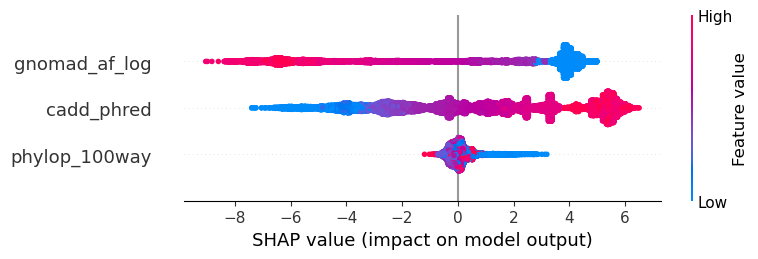

In [68]:
import shap

explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test)

In [69]:
vus_df.head()

,Type,Name,GeneSymbol,ClinicalSignificance,ClinSigSimple,PhenotypeList,Assembly,Chromosome,Start,Stop,ReferenceAllele,AlternateAllele,ReviewStatus,NumberSubmitters,label
25,single nucleotide variant,NM_000410.4(HFE):c.157G>A (p.Val53Met),HFE,Uncertain significance,0,HFE POLYMORPHISM|Hemochromatosis type 1|not pr...,GRCh38,6,26090921,26090921,na,na,"criteria provided, multiple submitters, no con...",3,NaN
27,single nucleotide variant,NM_000410.4(HFE):c.175G>A (p.Val59Met),HFE,Uncertain significance,0,HFE POLYMORPHISM|Hemochromatosis type 1|not sp...,GRCh38,6,26090939,26090939,na,na,"criteria provided, multiple submitters, no con...",3,NaN
77,single nucleotide variant,NM_001083961.2(WDR62):c.1576G>A (p.Glu526Lys),WDR62,Uncertain significance,1,"Microcephaly 2, primary, autosomal recessive, ...",GRCh38,19,36084678,36084678,na,na,"criteria provided, multiple submitters, no con...",11,NaN
131,single nucleotide variant,NM_000374.5(UROD):c.499G>A (p.Glu167Lys),UROD,Uncertain significance,1,Hepatoerythropoietic porphyria|not provided,GRCh38,1,45013933,45013933,na,na,"criteria provided, multiple submitters, no con...",3,NaN
277,single nucleotide variant,NM_033409.4(SLC52A3):c.1238T>C (p.Val413Ala),SLC52A3,Uncertain significance,1,Brown-Vialetto-van Laere syndrome 1|not specified,GRCh38,20,761198,761198,na,na,"criteria provided, multiple submitters, no con...",5,NaN


In [70]:
vus_df = vus_df.join(extra_cols)

vus_snv = vus_df[
    (vus_df["Type"] == "single nucleotide variant") &
    (vus_df["ReferenceAlleleVCF"] != "na") &
    (vus_df["AlternateAlleleVCF"] != "na")
].copy()

In [71]:
vus_snv["hgvs_id"] = (
    "chr" + vus_snv["Chromosome"].astype(str) + ":g." +
    vus_snv["PositionVCF"].astype(int).astype(str) +
    vus_snv["ReferenceAlleleVCF"] + ">" + vus_snv["AlternateAlleleVCF"]
)

In [72]:
print("VUS SNV sayısı:", vus_snv.shape)

VUS SNV sayısı: (293971, 19)


In [73]:
train_df.shape

(239580, 18)

In [74]:
url

'https://myvariant.info/v1/variant'

In [75]:
vus_ids = vus_snv["hgvs_id"].tolist()
batch_size = 1000
vus_results = []

for i in range(0, len(vus_ids), batch_size):
    batch = vus_ids[i:i+batch_size]
    r = requests.post(url, data={"ids": ",".join(batch), "fields": fields, "assembly": "hg38"})
    r.raise_for_status()
    vus_results.extend([flatten_result(x) for x in r.json()])
    print(f"{i+len(batch)}/{len(vus_ids)} tamamlandı")
    time.sleep(0.2)

vus_annot_df = pd.DataFrame(vus_results)
vus_annot_df.to_csv("vus_annot_checkpoint.csv", index=False)
print("Kaydedildi: vus_annot_checkpoint.csv")
print(vus_annot_df.shape)

1000/293971 tamamlandı
2000/293971 tamamlandı
3000/293971 tamamlandı
4000/293971 tamamlandı
5000/293971 tamamlandı
6000/293971 tamamlandı
7000/293971 tamamlandı
8000/293971 tamamlandı
9000/293971 tamamlandı
10000/293971 tamamlandı
11000/293971 tamamlandı
12000/293971 tamamlandı
13000/293971 tamamlandı
14000/293971 tamamlandı
15000/293971 tamamlandı
16000/293971 tamamlandı
17000/293971 tamamlandı
18000/293971 tamamlandı
19000/293971 tamamlandı
20000/293971 tamamlandı
21000/293971 tamamlandı
22000/293971 tamamlandı
23000/293971 tamamlandı
24000/293971 tamamlandı
25000/293971 tamamlandı
26000/293971 tamamlandı
27000/293971 tamamlandı
28000/293971 tamamlandı
29000/293971 tamamlandı
30000/293971 tamamlandı
31000/293971 tamamlandı
32000/293971 tamamlandı
33000/293971 tamamlandı
34000/293971 tamamlandı
35000/293971 tamamlandı
36000/293971 tamamlandı
37000/293971 tamamlandı
38000/293971 tamamlandı
39000/293971 tamamlandı
40000/293971 tamamlandı
41000/293971 tamamlandı
42000/293971 tamamlandı
4

HTTPError: 502 Server Error: Bad Gateway for url: https://myvariant.info/v1/variant

In [76]:
print(len(vus_results))

235000


In [77]:
resume_from = len(vus_results)  # 235000

for i in range(resume_from, len(vus_ids), batch_size):
    batch = vus_ids[i:i+batch_size]
    try:
        r = requests.post(url, data={"ids": ",".join(batch), "fields": fields, "assembly": "hg38"})
        r.raise_for_status()
        vus_results.extend([flatten_result(x) for x in r.json()])
        print(f"{i+len(batch)}/{len(vus_ids)} tamamlandı")
    except requests.exceptions.HTTPError as e:
        print(f"Hata (batch {i}), 5 saniye bekleyip tekrar deniyorum: {e}")
        time.sleep(5)
        try:
            r = requests.post(url, data={"ids": ",".join(batch), "fields": fields, "assembly": "hg38"})
            r.raise_for_status()
            vus_results.extend([flatten_result(x) for x in r.json()])
            print(f"{i+len(batch)}/{len(vus_ids)} tamamlandı (retry başarılı)")
        except requests.exceptions.HTTPError as e2:
            print(f"Retry de başarısız oldu, bu batch atlanıyor: {e2}")
    time.sleep(0.2)

vus_annot_df = pd.DataFrame(vus_results)
vus_annot_df.to_csv("vus_annot_checkpoint.csv", index=False)
print("Kaydedildi:", vus_annot_df.shape)

236000/293971 tamamlandı
237000/293971 tamamlandı
238000/293971 tamamlandı
239000/293971 tamamlandı
240000/293971 tamamlandı
241000/293971 tamamlandı
242000/293971 tamamlandı
243000/293971 tamamlandı
244000/293971 tamamlandı
245000/293971 tamamlandı
246000/293971 tamamlandı
247000/293971 tamamlandı
248000/293971 tamamlandı
249000/293971 tamamlandı
250000/293971 tamamlandı
251000/293971 tamamlandı
252000/293971 tamamlandı
253000/293971 tamamlandı
254000/293971 tamamlandı
255000/293971 tamamlandı
256000/293971 tamamlandı
257000/293971 tamamlandı
258000/293971 tamamlandı
259000/293971 tamamlandı
260000/293971 tamamlandı
261000/293971 tamamlandı
262000/293971 tamamlandı
263000/293971 tamamlandı
264000/293971 tamamlandı
265000/293971 tamamlandı
266000/293971 tamamlandı
267000/293971 tamamlandı
268000/293971 tamamlandı
269000/293971 tamamlandı
270000/293971 tamamlandı
271000/293971 tamamlandı
272000/293971 tamamlandı
273000/293971 tamamlandı
274000/293971 tamamlandı
275000/293971 tamamlandı


In [78]:
vus_annot_df.shape

(293971, 5)

In [80]:
vus_annot_df["notfound"].value_counts()

notfound
False    293906
True         65
Name: count, dtype: int64

In [81]:
vus_annot_clean = vus_annot_df[
    vus_annot_df["cadd_phred"].notna() & vus_annot_df["phylop_100way"].notna()
].copy()

In [82]:
vus_final = vus_snv.merge(vus_annot_clean, on="hgvs_id", how="inner")
vus_final["gnomad_af"] = vus_final["gnomad_af"].fillna(0)
vus_final["gnomad_af_log"] = np.log10(vus_final["gnomad_af"] + 1e-9)

In [83]:
print("Skorlanabilecek VUS sayısı:", vus_final.shape)


Skorlanabilecek VUS sayısı: (283429, 24)


In [84]:
vus_final.to_csv("vus_final_checkpoint.csv", index=False)

In [85]:
X_vus = vus_final[["cadd_phred", "phylop_100way", "gnomad_af_log"]]
vus_final["predicted_proba_pathogenic"] = best_model.predict_proba(X_vus)[:, 1]
vus_final["predicted_label"] = best_model.predict(X_vus)

In [86]:
vus_final[["hgvs_id", "GeneSymbol", "Name", "predicted_proba_pathogenic", "predicted_label"]].sort_values(
    "predicted_proba_pathogenic", ascending=False
).head(10)

,hgvs_id,GeneSymbol,Name,predicted_proba_pathogenic,predicted_label
231250,chr9:g.99137873G>T,TGFBR1,NM_004612.4(TGFBR1):c.589G>T (p.Val197Phe),0.999978,1
21235,chr16:g.2498380G>A,TBC1D24,NM_001199107.2(TBC1D24):c.1126G>A (p.Gly376Arg),0.999978,1
53948,chr14:g.23418254A>T,MYH7,NM_000257.4(MYH7):c.4125T>A (p.Tyr1375Ter),0.999973,1
143471,chr9:g.126691068G>A,LMX1B,NM_001174147.2(LMX1B):c.559G>A (p.Val187Met),0.999972,1
273071,chr7:g.55192841G>A,EGFR,NM_005228.5(EGFR):c.2701G>A (p.Gly901Arg),0.999972,1
63496,chr7:g.30600049G>A,GARS1,NM_002047.4(GARS1):c.427G>A (p.Gly143Ser),0.999971,1
266361,chr2:g.70963262G>T,ATP6V1B1,NM_001692.4(ATP6V1B1):c.1010G>T (p.Gly337Val),0.999971,1
16480,chr7:g.129017046G>A,TNPO3,NM_012470.4(TNPO3):c.332C>T (p.Ala111Val),0.999971,1
180171,chr10:g.102396726G>C,NFKB2,NM_001322934.2(NFKB2):c.146G>C (p.Arg49Thr),0.999969,1
40568,chr16:g.68833444G>A,CDH1,NM_004360.5(CDH1):c.2594G>A (p.Trp865Ter),0.999967,1


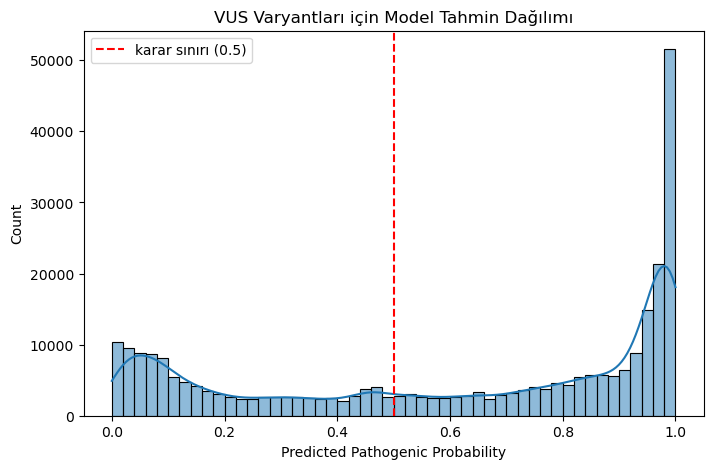

Pathogenic tahmini (>0.5): 176653
Benign tahmini (<0.5): 106776
Yüksek güvenle pathogenic (>0.9): 103046
Yüksek güvenle benign (<0.1): 45493


In [87]:
plt.figure(figsize=(8,5))
sns.histplot(vus_final["predicted_proba_pathogenic"], bins=50, kde=True)
plt.axvline(0.5, color="red", linestyle="--", label="karar sınırı (0.5)")
plt.xlabel("Predicted Pathogenic Probability")
plt.title("VUS Varyantları için Model Tahmin Dağılımı")
plt.legend()
plt.show()

print("Pathogenic tahmini (>0.5):", (vus_final["predicted_proba_pathogenic"] > 0.5).sum())
print("Benign tahmini (<0.5):", (vus_final["predicted_proba_pathogenic"] <= 0.5).sum())
print("Yüksek güvenle pathogenic (>0.9):", (vus_final["predicted_proba_pathogenic"] > 0.9).sum())
print("Yüksek güvenle benign (<0.1):", (vus_final["predicted_proba_pathogenic"] < 0.1).sum())

In [88]:
import joblib

joblib.dump(best_model, "xgb_model.pkl")
print("Model kaydedildi: xgb_model.pkl")

Model kaydedildi: xgb_model.pkl


In [89]:
vus_final.to_csv("vus_final_checkpoint.csv", index=False)

In [90]:
vus_final.columns.tolist()

['Type',
 'Name',
 'GeneSymbol',
 'ClinicalSignificance',
 'ClinSigSimple',
 'PhenotypeList',
 'Assembly',
 'Chromosome',
 'Start',
 'Stop',
 'ReferenceAllele',
 'AlternateAllele',
 'ReviewStatus',
 'NumberSubmitters',
 'label',
 'PositionVCF',
 'ReferenceAlleleVCF',
 'AlternateAlleleVCF',
 'hgvs_id',
 'cadd_phred',
 'gnomad_af',
 'phylop_100way',
 'notfound',
 'gnomad_af_log',
 'predicted_proba_pathogenic',
 'predicted_label']

In [92]:
print(results.keys())

dict_keys(['Logistic Regression (L2)', 'Logistic Regression (L1/Lasso)', 'Ridge Classifier', 'KNN', 'Naive Bayes', 'Linear SVM', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'AdaBoost', 'XGBoost', 'LightGBM'])


In [93]:
results_df = pd.DataFrame({name: scores for name, scores in results.items()})
results_summary = results_df.mean().sort_values(ascending=False)

In [94]:
import pickle

results_summary.to_csv("model_comparison.csv")

test_results = pd.DataFrame({
    "y_test": y_test.values,
    "y_pred": y_pred,
    "y_proba": y_proba
})
test_results.to_csv("test_predictions.csv", index=False)

with open("shap_data.pkl", "wb") as f:
    pickle.dump({"X_test": X_test, "shap_values": shap_values}, f)